# Unit I: Introduction

**Syllabus:** definition of data science, Big Data and the hype, datafication, current landscape of perspectives,
statistical inference, populations and samples, statistical modelling, probability distributions, fitting a model,
overfitting, Python environment for data science.

**Dataset:** UCI Adult (census income), the same data the TaskClean research runs on: 45,222 people, 14 features and one
target (`class`: does the person earn more than 50K a year?). This notebook only *reads* the project; the frozen
research phases in `src/` and `results/` are not touched.

In [1]:
import sys, pathlib
for _p in (pathlib.Path.cwd(), pathlib.Path.cwd() / "notebooks"):   # works from notebooks/ or the project root
    if (_p / "common.py").exists():
        sys.path.insert(0, str(_p)); break
from common import *
df = load_adult()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns (UCI Adult, natively-missing rows dropped)")

45,222 rows x 15 columns (UCI Adult, natively-missing rows dropped)


## 1.1 What is data science? Big Data hype and datafication

**Data science** = using statistics, programming and domain knowledge to turn data into decisions. It is usually drawn as
three overlapping skills: *maths/statistics*, *computing* and *domain expertise*. A fourth, often forgotten, is
*communication*: a result nobody understands changes nothing.

**Datafication** means turning something that was not data into data. A census form is the example in front of you: a person
(their job, marriage, education, hours of work) is turned into one row of numbers and labels. Once something is a row you
can count it, compare it, model it, and also *mis-measure* it, so every analysis starts by asking *who is in this table
and who is not*.

**Big Data hype.** "Big Data" is described by the 3 Vs (volume, velocity, variety). The hype says more data always means
better answers. In practice:
- most real problems are *small data* problems: this whole dataset is a few MB and fits in laptop memory;
- more rows do not fix **bad** rows. A biased or mislabelled sample stays biased at any size (the sampling demo below shows
  this). This is exactly the TaskClean research question: *which data-quality problems actually hurt the model?*
- getting past the hype means asking a precise question, checking data quality, and choosing the simplest method that
  answers it.

**Current landscape of perspectives.** Data science is practised as *statistics* (inference and uncertainty), *machine
learning* (prediction), *data engineering* (pipelines and storage) and *analytics/BI* (reporting). This course touches all
four; this notebook leans on the statistics view.

## 1.2 Populations and samples

A **population** is everything you want to know about; a **sample** is the part you actually observe. Statistics is the
bridge between them. Here we pretend the 45,222 rows are the *entire population* (so we know the true answer) and see what
samples of different sizes would have told us.

*What to look for:* sample means scatter around the true mean, the scatter shrinks like `sigma / sqrt(n)` (the
**standard error**), and the histogram of sample means looks bell-shaped even though the population is skewed (the
**Central Limit Theorem**).

In [2]:
pop = df["age"]
mu, sigma = pop.mean(), pop.std(ddof=0)
rng = np.random.default_rng(SEED)

sizes = [10, 30, 100, 500, 2000]
sample_means = {n: np.array([pop.sample(n, random_state=int(rng.integers(2**31))).mean() for _ in range(400)])
                for n in sizes}

table = pd.DataFrame({
    "sample size n": sizes,
    "mean of 400 sample means": [sample_means[n].mean() for n in sizes],
    "observed spread (std)": [sample_means[n].std() for n in sizes],
    "theory: sigma/sqrt(n)": [sigma / np.sqrt(n) for n in sizes],
}).round(3)
print(f"Population mean age = {mu:.3f}, population std = {sigma:.3f}")
table

Population mean age = 38.548, population std = 13.218


,sample size n,mean of 400 sample means,observed spread (std),theory: sigma/sqrt(n)
0,10,38.536,4.145,4.180
1,30,38.528,2.480,2.413
2,100,38.450,1.220,1.322
3,500,38.573,0.615,0.591
4,2000,38.567,0.300,0.296


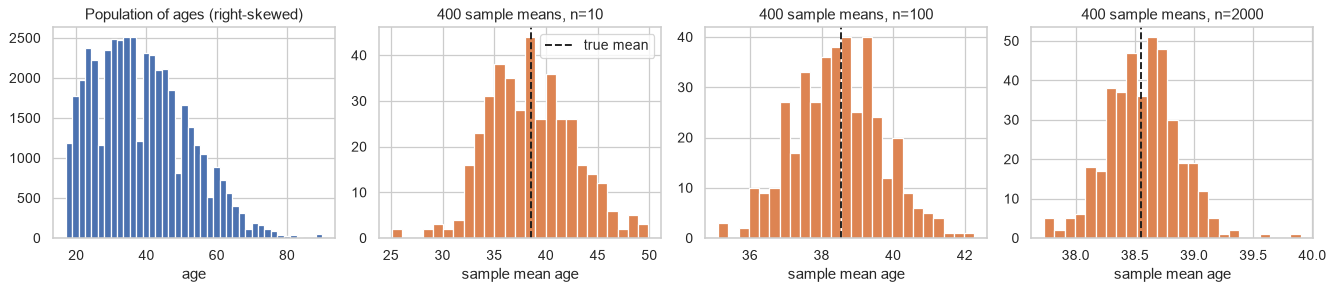

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=False)
axes[0].hist(pop, bins=40, color="C0")
axes[0].set(title="Population of ages (right-skewed)", xlabel="age")
for ax, n in zip(axes[1:], [10, 100, 2000]):
    ax.hist(sample_means[n], bins=25, color="C1")
    ax.axvline(mu, color="k", ls="--", label="true mean")
    ax.set(title=f"400 sample means, n={n}", xlabel="sample mean age")
axes[1].legend()
plt.show()

**Bias beats size.** A *random* sample estimates the population well. A *biased* sample (here, "only people who work 50+
hours answered the survey") is wrong, and getting more of it does not help.

In [4]:
true_high = (df[TARGET] == ">50K").mean()
random_s = df.sample(2000, random_state=SEED)
biased_s = df[df["hours-per-week"] >= 50].sample(2000, random_state=SEED)

pd.DataFrame({
    "mean age": [mu, random_s["age"].mean(), biased_s["age"].mean()],
    "share earning >50K": [true_high, (random_s[TARGET] == ">50K").mean(), (biased_s[TARGET] == ">50K").mean()],
}, index=["population (45,222)", "random sample (2,000)", "biased sample (2,000, hours>=50)"]).round(3)

,mean age,share earning >50K
"population (45,222)",38.548,0.248
"random sample (2,000)",38.414,0.254
"biased sample (2,000, hours>=50)",40.414,0.421


## 1.3 Statistical inference

**Inference** = drawing conclusions about a population from a sample, *with a measure of uncertainty*. Two standard tools:

1. **Confidence interval (CI).** A 95% CI is built so that, over many repeated samples, about 95% of the intervals contain
   the true value. We can check that claim here because we know the true population mean.
2. **Hypothesis test.** Start from a *null hypothesis* H0 ("no difference"), compute how surprising the data would be if H0
   were true (the **p-value**), and reject H0 if it is very small. The p-value is *not* the probability that H0 is true.

In [5]:
from scipy import stats

x = df["hours-per-week"]
true_mu = x.mean()
n, reps, hits = 200, 1000, 0
for i in range(reps):
    s = x.sample(n, random_state=i)
    lo, hi = stats.t.interval(0.95, n - 1, loc=s.mean(), scale=stats.sem(s))
    hits += lo <= true_mu <= hi
print(f"True mean hours/week = {true_mu:.2f}")
print(f"{hits}/{reps} of the 95% intervals contained it  ->  coverage {hits / reps:.1%} (target 95%)")

s = x.sample(n, random_state=0)
lo, hi = stats.t.interval(0.95, n - 1, loc=s.mean(), scale=stats.sem(s))
print(f"One sample of {n}: mean {s.mean():.2f}, 95% CI [{lo:.2f}, {hi:.2f}]")

True mean hours/week = 40.94
951/1000 of the 95% intervals contained it  ->  coverage 95.1% (target 95%)
One sample of 200: mean 41.10, 95% CI [39.27, 42.93]


**Hypothesis test 1: do men and women report different weekly hours?** (Welch two-sample t-test: compares two means
without assuming equal variances.) **Cohen's d** measures the *size* of the difference in standard deviations. With
45,000 rows even a small gap gives a tiny p-value, so always report the effect size too: *statistically significant is not
the same as practically important*.

In [6]:
men = df.loc[df["sex"] == "Male", "hours-per-week"]
women = df.loc[df["sex"] == "Female", "hours-per-week"]
t, p = stats.ttest_ind(men, women, equal_var=False)
d = (men.mean() - women.mean()) / np.sqrt((men.var() + women.var()) / 2)
print(f"Full data : men {men.mean():.2f} h vs women {women.mean():.2f} h | t = {t:.1f}, {fmt_p(p)}, Cohen's d = {d:.2f}")

# same question with only 50 people per group: the *same* true gap, much weaker evidence
m50, w50 = men.sample(50, random_state=1), women.sample(50, random_state=1)
t50, p50 = stats.ttest_ind(m50, w50, equal_var=False)
print(f"50 per group: men {m50.mean():.2f} h vs women {w50.mean():.2f} h | t = {t50:.1f}, p = {p50:.3g}")

Full data : men 42.87 h vs women 36.93 h | t = 50.9, p < 1e-300, Cohen's d = 0.51
50 per group: men 42.22 h vs women 37.74 h | t = 1.7, p = 0.0886


**Hypothesis test 2: is income independent of sex?** (Chi-square test of independence on a contingency table;
**Cramér's V** is the effect size, 0 = no association, 1 = perfect.)

In [7]:
ct = pd.crosstab(df["sex"], df[TARGET])
chi2, p, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
display(ct)
print(f"chi2 = {chi2:.1f}, dof = {dof}, {fmt_p(p)}, Cramer's V = {cramers_v:.3f}")
print("Share earning >50K:", (ct[">50K"] / ct.sum(axis=1)).round(3).to_dict())

class,<=50K,>50K
sex,,
Female,13026,1669
Male,20988,9539


chi2 = 2104.1, dof = 1, p < 1e-300, Cramer's V = 0.216
Share earning >50K: {'Female': 0.114, 'Male': 0.312}


## 1.4 Probability distributions

A **probability distribution** describes how likely each value is. *Continuous* attributes are described by a density
(normal, log-normal, ...), *discrete* ones by a mass function (Bernoulli, binomial, ...). Many methods assume
approximately normal data, so we *check* rather than assume: histogram + fitted curve, a Q-Q plot (points on the line
means "looks normal"), skewness and a formal test.

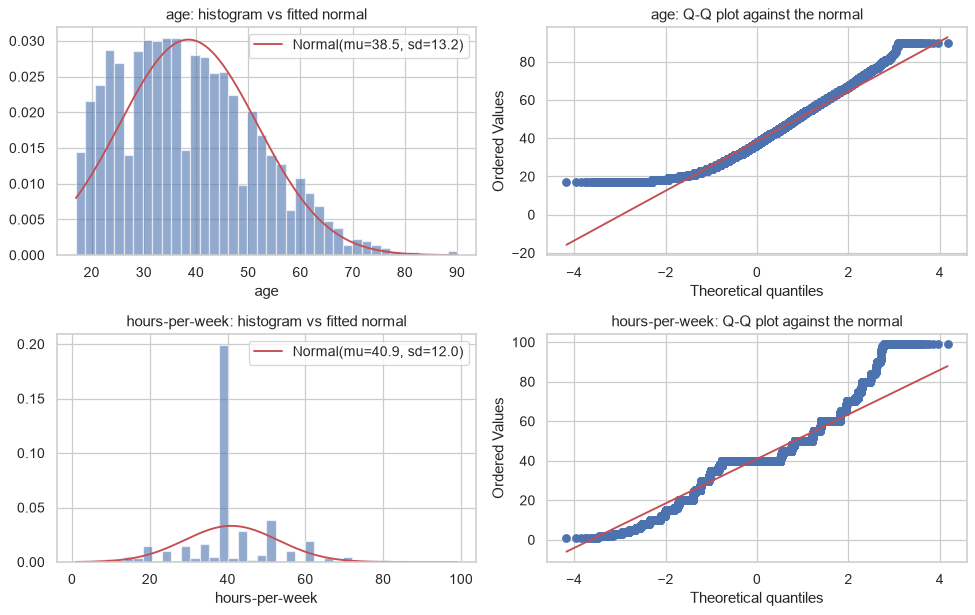

,column,skewness,excess kurtosis,Shapiro-Wilk p (n=2000)
0,age,0.533,-0.156,4.5e-22
1,hours-per-week,0.341,3.201,6.7e-38
2,education-num,-0.311,0.635,1.1e-29
3,capital-gain,11.789,150.135,3.5e-70


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, col in enumerate(["age", "hours-per-week"]):
    v = df[col]
    m, s = stats.norm.fit(v)
    grid = np.linspace(v.min(), v.max(), 300)
    axes[row, 0].hist(v, bins=40, density=True, alpha=.6)
    axes[row, 0].plot(grid, stats.norm.pdf(grid, m, s), "r", label=f"Normal(mu={m:.1f}, sd={s:.1f})")
    axes[row, 0].set(title=f"{col}: histogram vs fitted normal", xlabel=col)
    axes[row, 0].legend()
    stats.probplot(v, dist="norm", plot=axes[row, 1])
    axes[row, 1].set_title(f"{col}: Q-Q plot against the normal")
plt.show()

rows = []
for col in ["age", "hours-per-week", "education-num", "capital-gain"]:
    v = df[col]
    w, p = stats.shapiro(v.sample(2000, random_state=SEED))
    rows.append({"column": col, "skewness": stats.skew(v), "excess kurtosis": stats.kurtosis(v), "Shapiro-Wilk p (n=2000)": f"{p:.1e}"})
pd.DataFrame(rows).round(3)

Reading the table: skewness near 0 and kurtosis near 0 means normal-like; `age` is right-skewed and `capital-gain` is
extremely skewed (92% zeros), so methods that assume normality should be used with care on them. `hours-per-week` has a huge
spike at 40 (a *mode*, not a bell). Shapiro-Wilk p-values are essentially 0 for all four: **none of them is normal**, which
is normal for real data.

**Discrete distributions.** Whether one person earns >50K is a *Bernoulli* trial with p ~ 0.25. The number of high earners in
a random group of 20 is therefore *Binomial(20, p)*. The theory should match a simulation:

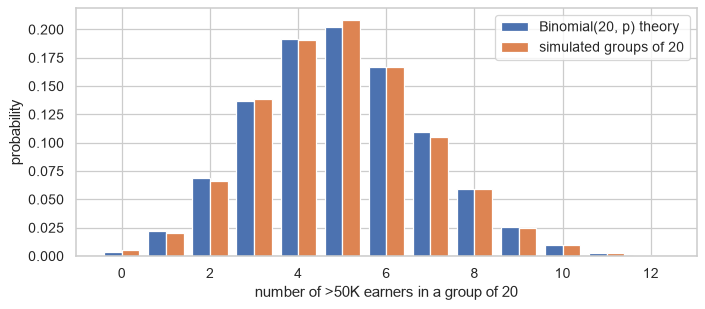

p = 0.248; P(8 or more of 20 earn >50K) = 0.0977


In [9]:
p_high = (df[TARGET] == ">50K").mean()
k = np.arange(0, 13)
theory = stats.binom.pmf(k, 20, p_high)
sim = rng.choice((df[TARGET] == ">50K").to_numpy(), size=(5000, 20)).sum(axis=1)
empirical = np.array([(sim == i).mean() for i in k])

plt.figure(figsize=(8, 3.6))
plt.bar(k - 0.2, theory, width=0.4, label="Binomial(20, p) theory")
plt.bar(k + 0.2, empirical, width=0.4, label="simulated groups of 20")
plt.xlabel("number of >50K earners in a group of 20"); plt.ylabel("probability"); plt.legend()
plt.show()
print(f"p = {p_high:.3f}; P(8 or more of 20 earn >50K) = {stats.binom.sf(7, 20, p_high):.4f}")

## 1.5 Statistical modelling and fitting a model

A **model** is a simplified mathematical description of how the target depends on the features. **Fitting** means choosing
the model's parameters so it matches the data. For a logistic regression, the parameters are one coefficient per
feature; `exp(coefficient)` is an **odds ratio** (how much the odds of earning >50K are multiplied when that feature
increases by one unit, or is "on" for a one-hot feature).

We use the *same 70/15/15 stratified split and preprocessing as the research phases* (`three_way_split`,
`build_preprocessor` from `src/`, imported read-only), so these models are comparable with the project's baseline.

In [10]:
from data import three_way_split
from baseline import build_preprocessor
from sklearn.linear_model import LogisticRegression

X, y = df.drop(columns=TARGET), df[TARGET]
X_tr, X_va, X_te, y_tr, y_va, y_te = three_way_split(X, y, seed=SEED)
prep = build_preprocessor(X_tr)
Z_tr, Z_va, Z_te = prep.fit_transform(X_tr), prep.transform(X_va), prep.transform(X_te)
print(f"train {len(X_tr):,} | validation {len(X_va):,} | test {len(X_te):,}  ->  {Z_tr.shape[1]} model features after encoding")

lr = LogisticRegression(max_iter=1000, random_state=SEED).fit(Z_tr, y_tr)
coef = pd.Series(lr.coef_[0], index=[n.split("__", 1)[1] for n in prep.get_feature_names_out()])
odds = np.exp(coef).sort_values()
rows_in_level = pd.Series(np.asarray(Z_tr.sum(axis=0)).ravel(), index=coef.index).drop(NUMERIC, errors="ignore")  # one-hot columns only
summary = pd.DataFrame({"odds ratio": odds, "training rows with this level": rows_in_level.reindex(odds.index)})
print("Lowest and highest odds ratios (a ratio below 1 lowers the odds of earning >50K, above 1 raises them):")
pd.concat([summary.head(7), summary.tail(7)]).round(2)

train 31,655 | validation 6,783 | test 6,784  ->  104 model features after encoding
Lowest and highest odds ratios (a ratio below 1 lowers the odds of earning >50K, above 1 raises them):


,odds ratio,training rows with this level
native-country_Columbia,0.20,59.0
marital-status_Never-married,0.32,10175.0
relationship_Own-child,0.33,4631.0
occupation_Farming-fishing,0.38,1042.0
occupation_Priv-house-serv,0.41,149.0
sex_Female,0.41,10268.0
native-country_South,0.43,68.0
occupation_Exec-managerial,2.35,4206.0
native-country_Cambodia,2.38,22.0
relationship_Wife,2.67,1433.0


Numeric features were standardised, so their odds ratio is per **one standard deviation** (`capital-gain` has the largest
effect: +1 SD multiplies the odds by about 10). Among the categories, *never married*, *own child at home*, *farming/fishing*
and *female* lower the odds (ratios around 0.3-0.4), while *married (civil spouse)*, *wife* and *executive/managerial* raise
them (about 2.4-3.5). **Caution:** levels with very few training rows (e.g. `native-country_Columbia` with 59,
`Married-AF-spouse` with 22) give extreme but unstable ratios, which is why the table shows how many rows each level rests
on. That is a *fitted statistical model*: an interpretable summary and a predictor. (These are associations in this
sample, not causes.)

## 1.6 Overfitting

A model that is too flexible memorises the training data (including its noise) and then does worse on new data. The
symptom is a **growing gap between training and validation accuracy**. A decision tree makes this easy to see: its
`max_depth` is a dial from *underfit* (too simple) through *good fit* to *overfit* (memorises).

The rule that keeps us honest, and that the whole project follows: **choose the model setting on the validation set, and
touch the test set only once at the very end.**

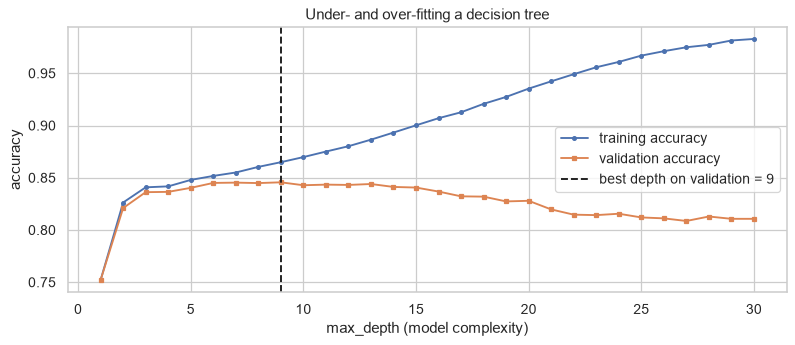

Chosen depth 9: train 0.865 | val 0.846 | TEST (used once) 0.856
Fully grown tree (depth 30): train 0.983 vs val 0.811 -> gap 0.172


In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

depths = list(range(1, 31))
train_acc, val_acc = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(Z_tr, y_tr)
    train_acc.append(accuracy_score(y_tr, tree.predict(Z_tr)))
    val_acc.append(accuracy_score(y_va, tree.predict(Z_va)))

best = depths[int(np.argmax(val_acc))]
plt.figure(figsize=(9, 4))
plt.plot(depths, train_acc, "o-", ms=3, label="training accuracy")
plt.plot(depths, val_acc, "s-", ms=3, label="validation accuracy")
plt.axvline(best, color="k", ls="--", label=f"best depth on validation = {best}")
plt.xlabel("max_depth (model complexity)"); plt.ylabel("accuracy"); plt.legend(); plt.title("Under- and over-fitting a decision tree")
plt.show()

final = DecisionTreeClassifier(max_depth=best, random_state=SEED).fit(Z_tr, y_tr)
print(f"Chosen depth {best}: train {accuracy_score(y_tr, final.predict(Z_tr)):.3f} | "
      f"val {max(val_acc):.3f} | TEST (used once) {accuracy_score(y_te, final.predict(Z_te)):.3f}")
print(f"Fully grown tree (depth {30}): train {train_acc[-1]:.3f} vs val {val_acc[-1]:.3f} -> gap {train_acc[-1] - val_acc[-1]:.3f}")

In [12]:
from sklearn.ensemble import RandomForestClassifier

rows = []
for name, model in {"Random Forest, unlimited depth": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
                    "Random Forest, max_depth=8": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=SEED, n_jobs=-1)}.items():
    model.fit(Z_tr, y_tr)
    tr, va = accuracy_score(y_tr, model.predict(Z_tr)), accuracy_score(y_va, model.predict(Z_va))
    rows.append({"model": name, "train accuracy": tr, "validation accuracy": va, "gap (overfit)": tr - va})
pd.DataFrame(rows).round(3)

,model,train accuracy,validation accuracy,gap (overfit)
0,"Random Forest, unlimited depth",1.000,0.842,0.158
1,"Random Forest, max_depth=8",0.854,0.847,0.007


**Take-away.** The unlimited forest scores ~100% on data it has seen but only ~84% on new data: the gap is the overfit.
A depth-limited forest has almost no gap and is just as accurate (even slightly better) on validation data. This is why the research phases:
(a) evaluate only on a *clean test split that is never corrupted or repaired*, and (b) judge repairs by *out-of-fold*
predictions, never by accuracy on the data a model was trained on.

## 1.7 Python environment for data science

A project should run in an isolated **virtual environment** so that its library versions do not clash with other
projects or the operating system's Python (macOS refuses a global `pip install`, which is exactly the error you hit).

```bash
python3 -m venv .venv                         # create the environment
source .venv/bin/activate                     # activate it (prompt shows (.venv))
pip install -r requirements-notebook.txt      # install the libraries
```
In VS Code choose the interpreter with *Cmd+Shift+P -> Python: Select Interpreter -> .venv*, and select the same `.venv` as
the notebook kernel (top-right of the notebook). The core stack is **NumPy** (arrays), **pandas** (tables), **SciPy**
(statistics), **scikit-learn** (models), **Matplotlib/Seaborn** (plots) and **Jupyter** (notebooks).

In [13]:
import platform, sys
import importlib.metadata as md

print("Python  :", sys.version.split()[0], "|", platform.platform())
print("Inside a virtual environment:", sys.prefix != sys.base_prefix, "->", sys.prefix)
pd.DataFrame({"library": (libs := ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn", "ipykernel"]),
              "version": [md.version(l) for l in libs]})

Python  : 3.14.6 | macOS-27.0.1-arm64-arm-64bit-Mach-O
Inside a virtual environment: True -> /Users/ishikamahadar/Documents/Documents/Projects /DSc CP/.venv


,library,version
0,numpy,2.5.3
1,pandas,3.0.6
2,scipy,1.18.1
3,scikit-learn,1.9.1
4,matplotlib,3.11.2
5,seaborn,0.13.2
6,ipykernel,7.4.0
